In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph

In [2]:
class AgentState(TypedDict):
    name: str
    age: str
    final: str

In [ ]:
def one(state: AgentState) -> AgentState:
    state["final"] = f"{state['name']} Hi!"
    return state

In [9]:
def two(state: AgentState) -> AgentState:
    state["final"] += f" You're {state['age']}"
    return state

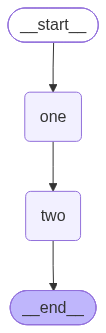

In [10]:
graph = StateGraph(AgentState)

graph.add_node("one", one)
graph.add_node("two", two)
graph.add_edge("one", "two")
graph.set_entry_point("one")
graph.set_finish_point("two")

app = graph.compile()
app

In [11]:
results = app.invoke({"name": "Maaz", "age": "20"})

In [12]:
results

{'name': 'Maaz', 'age': '20', 'final': "Maaz Hi! You're 20"}